# Task 9: Industrial Predictive Maintenance

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, ConfusionMatrixDisplay
import joblib

In [2]:
df = pd.read_csv("ai4i2020.csv")
df.columns = df.columns.str.strip()
print("Shape:", df.shape)
display(df.head())

Shape: (10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

## Data Preparation and cleaning

In [4]:
df = df.dropna(subset=["Machine failure"]).copy()
y = pd.to_numeric(df["Machine failure"], errors="coerce")

In [5]:
non_features = ["UDI", "Product ID","Machine failure" , "TWF", "HDF", "PWF", "OSF", "RNF"]
X = df.drop(columns=non_features)
X = X.select_dtypes(include=["number"]).replace([np.inf, -np.inf], np.nan)
print("Target distribution:"); display(y.value_counts().rename(index={0:"No failure",1:"Failure"}))
print("Predictor columns:", X.columns.tolist())

Target distribution:


Machine failure
No failure    9661
Failure        339
Name: count, dtype: int64

Predictor columns: ['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]']


In [6]:
valid = y.notna()
df, y = df.loc[valid].copy(), y.loc[valid].astype(int)

## Split into training, validation and test sets
The test set is held back until the decision threshold has been selected on validation data.

In [7]:
X_trainval, X_test, y_trainval, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_trainval, y_trainval, test_size=0.25, random_state=42, stratify=y_trainval)
print("Train:", X_train.shape, "Validation:", X_val.shape, "Test:", X_test.shape)

Train: (6000, 5) Validation: (2000, 5) Test: (2000, 5)


## Training a class-balanced Random Forest

In [8]:
model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", min_samples_leaf=2, random_state=42, n_jobs=-1))
])

In [9]:
model.fit(X_train, y_train)
val_prob = model.predict_proba(X_val)[:, 1]
print("Validation probabilities generated:", len(val_prob))

Validation probabilities generated: 2000


## Selecting a probability threshold with false discovery rate in mind
False Discovery Rate (FDR) = FP / (TP + FP) = 1 − precision. The following chooses the lowest validation FDR among thresholds that achieve at least 50% recall, where possible. This is a trade-off, not a universal operational setting.

In [10]:
threshold_rows = []
for threshold in np.arange(0.10, 0.91, 0.05):
    val_pred = (val_prob >= threshold).astype(int)
    precision = precision_score(y_val, val_pred, zero_division=0)
    recall = recall_score(y_val, val_pred, zero_division=0)
    fdr = 1 - precision if val_pred.sum() else 0.0
    threshold_rows.append({"threshold":round(float(threshold),2),"precision":precision,"recall":recall,"FDR":fdr})

In [11]:
threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.head())

,threshold,precision,recall,FDR
0,0.10,0.282927,0.852941,0.717073
1,0.15,0.355828,0.852941,0.644172
2,0.20,0.409091,0.794118,0.590909
3,0.25,0.446429,0.735294,0.553571
4,0.30,0.505263,0.705882,0.494737


In [12]:
eligible = threshold_table[threshold_table["recall"] >= 0.50]
chosen = eligible.sort_values(["FDR", "recall"], ascending=[True, False]).iloc[0]

In [13]:
threshold = float(chosen["threshold"])
print("Selected threshold:", threshold)

Selected threshold: 0.55


## Refit on training plus validation data and evaluate once on test set

In [14]:
final_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample", min_samples_leaf=2, random_state=42, n_jobs=-1))
])

In [15]:
final_model.fit(X_trainval, y_trainval)

,steps,"[('imputer', ...), ('scaler', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,missing_values,nan
,strategy,'median'
,fill_value,None
,copy,True
,add_indicator,False
,keep_empty_features,False
,copy,True


In [16]:
test_prob = final_model.predict_proba(X_test)[:, 1]
test_pred = (test_prob >= threshold).astype(int)

In [17]:
precision = precision_score(y_test, test_pred, zero_division=0)
recall = recall_score(y_test, test_pred, zero_division=0)
fdr = 1 - precision if test_pred.sum() else 0.0

In [18]:
metrics = pd.DataFrame([{"Threshold":threshold,"Accuracy":accuracy_score(y_test,test_pred),"Precision":precision,"Recall":recall,"F1":f1_score(y_test,test_pred,zero_division=0),"False Discovery Rate":fdr}])
display(metrics)
print(classification_report(y_test, test_pred, zero_division=0))

,Threshold,Accuracy,Precision,Recall,F1,False Discovery Rate
0,0.55,0.9835,0.857143,0.617647,0.717949,0.142857


              precision    recall  f1-score   support

           0       0.99      1.00      0.99      1932
           1       0.86      0.62      0.72        68

    accuracy                           0.98      2000
   macro avg       0.92      0.81      0.85      2000
weighted avg       0.98      0.98      0.98      2000



## Visualise confusion matrix and feature importance

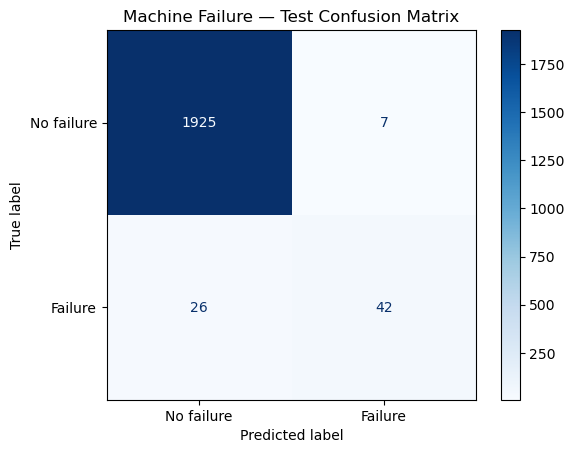

In [19]:
ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=["No failure","Failure"], cmap="Blues")
plt.title("Machine Failure — Test Confusion Matrix"); 
plt.show();

In [20]:
classifier = final_model.named_steps["classifier"]
importance = pd.Series(classifier.feature_importances_, index=X.columns).sort_values()

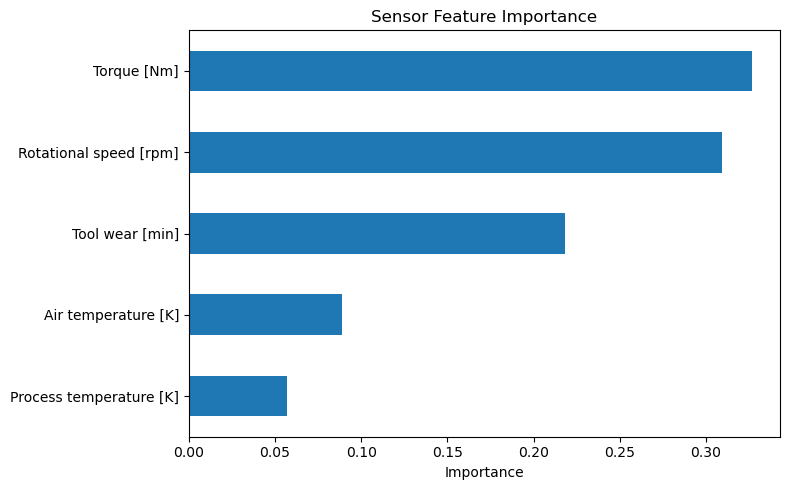

In [21]:
importance.plot(kind="barh", figsize=(8,5), title="Sensor Feature Importance")
plt.xlabel("Importance"); plt.tight_layout(); plt.show()

In [22]:
prediction_output = pd.DataFrame({"Actual":y_test, "Failure_Probability":test_prob, "Predicted_Failure":test_pred}, index=y_test.index)
prediction_output.to_csv("maintenance_test_predictions.csv", index=False)

In [23]:
metrics.to_csv("maintenance_test_metrics.csv", index=False)
threshold_table.to_csv("validation_threshold_analysis.csv", index=False)

In [24]:
joblib.dump({"model":final_model,"threshold":threshold,"features":list(X.columns)}, "predictive_maintenance_model.joblib")
print("Saved predictions, metrics, threshold analysis and trained model.")

Saved predictions, metrics, threshold analysis and trained model.


## Conclusion
At a threshold of 0.55, the model is highly precised with a low FDR, but the recall shows it misses 38% of true positives, resulting in an F1-score of 0.718 despite an accuracy of 0.984. A false positive may cause an unnecessary inspection; a false negative may allow a failure to go undetected.